# 01 · Agentes y panorama de la IA

**Objetivo:** fijar el vocabulario que organiza todo el curso (agente, entorno, medida de
desempeño) y ver experimentalmente por qué un agente con **modelo del mundo** supera a uno reactivo.

## Panorama histórico (muy resumido)

| Época | Idea dominante | Hitos |
|---|---|---|
| 1943–1956 | Nacimiento | Neurona de McCulloch–Pitts (1943), test de Turing (1950), Dartmouth (1956) |
| 1956–1974 | IA simbólica, búsqueda | Logic Theorist, GPS, perceptrón (1958), LISP |
| 1974–1980 | Primer invierno | Límites del perceptrón (Minsky–Papert, 1969), informe Lighthill (1973) |
| 1980–1987 | Sistemas expertos | Reglas + motores de inferencia en la industria (XCON) |
| 1987–1993 | Segundo invierno | Fragilidad y costo de mantener bases de reglas |
| 1990–2011 | IA probabilística y ML | Redes bayesianas, SVM, Deep Blue (1997) |
| 2012– | Aprendizaje profundo | AlexNet (2012), AlphaGo (2016), transformers (2017) |
| 2020– | Modelos fundacionales | GPT-3 (2020), LLMs con herramientas y agentes |

Dos tradiciones conviven: la **simbólica** (representar conocimiento y razonar: este módulo) y la
**conexionista/estadística** (aprender de datos: el resto de S1). Los agentes basados en LLM las
combinan: un modelo aprendido que planifica y llama herramientas deterministas.

## Agente, entorno y PEAS

Un **agente** es una función de la historia de percepciones a acciones. Se diseña especificando
**PEAS**: medida de desempeño, entorno, actuadores, sensores.

| Propiedad del entorno | Aspiradora (aquí) | Pathfinding (proyecto) | Agente LLM con herramientas |
|---|---|---|---|
| Observable | parcial | total | parcial (solo ve lo que las herramientas devuelven) |
| Determinista | no (aparece suciedad) | sí | no |
| Episódico / secuencial | secuencial | secuencial | secuencial |
| Estático / dinámico | dinámico | estático | dinámico |
| Discreto / continuo | discreto | discreto | discreto (texto) |
| Un agente / varios | uno | uno | uno o varios |

Cuanto más a la derecha en esta tabla (parcial, estocástico, dinámico), más necesita el agente
un **estado interno**: es exactamente el papel de la “memoria” o el contexto en un agente LLM.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from ai_foundations.agents import (
    VacuumWorld,
    model_based_agent,
    random_agent,
    run_episode,
    simple_reflex_agent,
)

## Mundo de la aspiradora

Grilla 6×6; cada celda se ensucia con probabilidad `dirt_prob` por paso. El agente solo
percibe su posición y si *su* celda está sucia. Tres agentes:

- **Aleatorio**: línea base.
- **Reflejo simple**: si está sucio aspira; si no, se mueve al azar. Sin memoria.
- **Basado en modelo**: recuerda cuándo visitó cada celda y va hacia la visitada hace más tiempo.

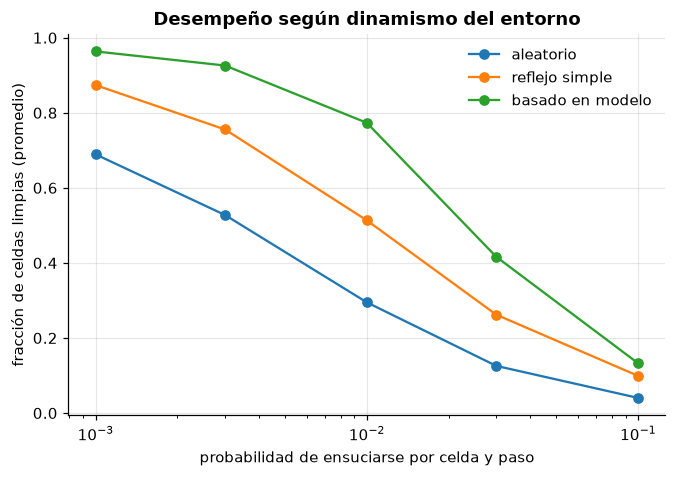

In [2]:
AGENTS = {
    "aleatorio": lambda: random_agent(np.random.default_rng(0)),
    "reflejo simple": lambda: simple_reflex_agent(np.random.default_rng(0)),
    "basado en modelo": lambda: model_based_agent(6, 6),
}


def evaluate(make_agent, dirt_prob, seeds=range(5), steps=800):
    scores = []
    for s in seeds:
        world = VacuumWorld(6, 6, dirt_prob=dirt_prob, rng=np.random.default_rng(s))
        scores.append(run_episode(make_agent(), world, steps).clean_fraction)
    return np.mean(scores)


probs = [0.001, 0.003, 0.01, 0.03, 0.1]
fig, ax = plt.subplots()
for name, make in AGENTS.items():
    ax.plot(probs, [evaluate(make, p) for p in probs], "o-", label=name)
ax.set_xscale("log")
ax.set_xlabel("probabilidad de ensuciarse por celda y paso")
ax.set_ylabel("fracción de celdas limpias (promedio)")
ax.set_title("Desempeño según dinamismo del entorno")
ax.legend();

Lectura:
- Con entorno casi estático, la memoria permite al agente basado en modelo “barrer” sistemáticamente.
- Al aumentar la suciedad, ningún agente da abasto (una aspiradora para 36 celdas) y las curvas
  convergen: el límite pasa a ser el entorno, no la inteligencia del agente.
- El reflejo simple es **racional solo si el entorno es totalmente observable**; aquí no lo es.

## Para llevar

- Racionalidad = maximizar la medida de desempeño *esperada* dada la información disponible.
- La arquitectura del agente (reflejo, modelo, metas, utilidad, aprendizaje) debe corresponder
  a las propiedades del entorno.
- Un agente LLM es un agente basado en modelo y metas en un entorno parcialmente observable:
  el contexto es su estado interno y las herramientas, sus actuadores.